<a href="https://colab.research.google.com/github/ryanaxiom/Applied-ML/blob/main/code/Day25_Carnegie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Instructions**: Before you begin, click **File > Save a copy in Drive** so you do not lose your work!

In [1]:
url = ("https://raw.githubusercontent.com/ryanaxiom/"
       "Applied-ML/main/data/carnegie_data.csv")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
carnegie_raw = pd.read_csv(url, encoding="cp1252")
carnegie = carnegie_raw.copy()
carnegie["research"] = carnegie["serd"] + carnegie["nonserd"]
d = carnegie[carnegie["research"].notna()].copy()
d["med_yn"] = (d["medical"] == 1).astype(int)
y = d["research"]
kf = KFold(n_splits=5, shuffle=True, random_state=309)
five = ["fallenr20", "totdeg", "facnum", "stem_rsd", "med_yn"]
print(carnegie.shape, d.shape)

(3939, 102) (302, 103)


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
four = ["fallenr20", "totdeg", "facnum", "stem_rsd"]
scaler4 = StandardScaler()
Z4 = scaler4.fit_transform(d[four])
pca4 = PCA()
pca4.fit(Z4)
print(pca4.explained_variance_ratio_.round(4))
print(pca4.components_[:2].round(2))            # PC1 row, PC2 row

[0.7808 0.1328 0.079  0.0075]
[[ 0.52  0.54  0.47  0.47]
 [-0.54 -0.4   0.55  0.5 ]]


In [3]:
def first_axis(X):
    pca = PCA()
    pca.fit(X)
    w = pd.Series(pca.components_[0], index=X.columns).abs()
    print(round(float(pca.explained_variance_ratio_[0]), 4),
          w.idxmax(), round(float(w.max()), 3))
first_axis(d[four])                             # no scaler
thousands = d[four].copy()
thousands["fallenr20"] = thousands["fallenr20"] / 1000
first_axis(thousands)                   # same campuses, new units
first_axis(pd.DataFrame(Z4, columns=four))      # standardized
print(d[four].std().round(0).values)            # the four SDs

0.9932 fallenr20 0.965
0.976 totdeg 0.989
0.7808 totdeg 0.536
[14835.  4124.   886.   131.]


In [4]:
from sklearn.pipeline import make_pipeline
for name, V in [("raw", d[four]), ("thousands", thousands),
                ("standardized", pd.DataFrame(Z4, columns=four))]:
    p = PCA()
    p.fit(V)
    print(name, pd.Series(p.components_[0], index=four).round(3).to_dict())
scaled_pca = make_pipeline(StandardScaler(), PCA())
scaled_pca.fit(thousands)                  # any units in, the same axes out
print(scaled_pca[-1].explained_variance_ratio_.round(4))

raw {'fallenr20': 0.965, 'totdeg': 0.26, 'facnum': 0.035, 'stem_rsd': 0.005}
thousands {'fallenr20': 0.003, 'totdeg': 0.989, 'facnum': 0.147, 'stem_rsd': 0.022}
standardized {'fallenr20': 0.516, 'totdeg': 0.536, 'facnum': 0.47, 'stem_rsd': 0.474}
[0.7808 0.1328 0.079  0.0075]


JHU 2.74 1.57
WVU 0.44 -0.15
MIT 0.8 1.98
Marshall -1.18 0.04


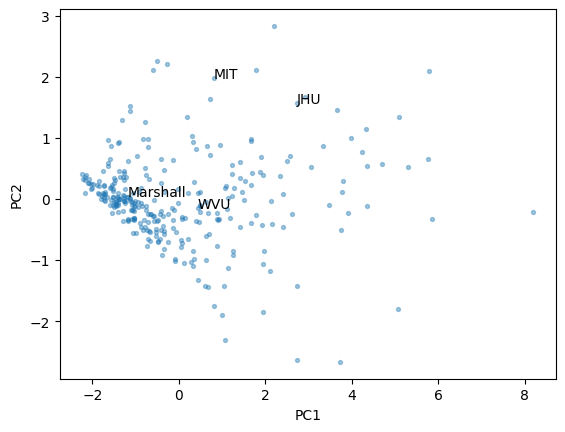

In [5]:
scores = pca4.transform(Z4)               # 302 rows, 4 new columns
plt.scatter(scores[:, 0], scores[:, 1], s=8, alpha=0.4)
labels = {"Johns Hopkins University": "JHU",
          "West Virginia University": "WVU",
          "Massachusetts Institute of Technology": "MIT",
          "Marshall University": "Marshall"}
for full, short in labels.items():
    i = np.where(d["name"] == full)[0][0]
    plt.annotate(short, scores[i, :2])
    print(short, *scores[i, :2].round(2))       # PC1, PC2
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

In [6]:
pc2 = pd.Series(scores[:, 1], index=d["name"].values)
print(int(pc2.rank(ascending=False)["Massachusetts Institute of Technology"]), "of", len(pc2))
print(pc2.sort_values(ascending=False).head(5).round(2).to_dict())
print(pc2.sort_values().head(5).round(2).to_dict())
print(round(float(np.corrcoef(scores[:, 0], y)[0, 1]), 4),
      round(float(np.corrcoef(scores[:, 1], y)[0, 1]), 4))

7 of 302
{'Stanford University': 2.83, 'Icahn School of Medicine at Mount Sinai': 2.25, 'University of California-San Francisco': 2.21, 'Duke University': 2.11, 'Baylor College of Medicine': 2.11}
{'University of Central Florida': -2.67, 'Florida International University': -2.63, 'Arizona State University Digital Immersion': -2.32, 'California State University-Fullerton': -1.89, 'The University of Texas at Arlington': -1.86}
0.6834 0.5207


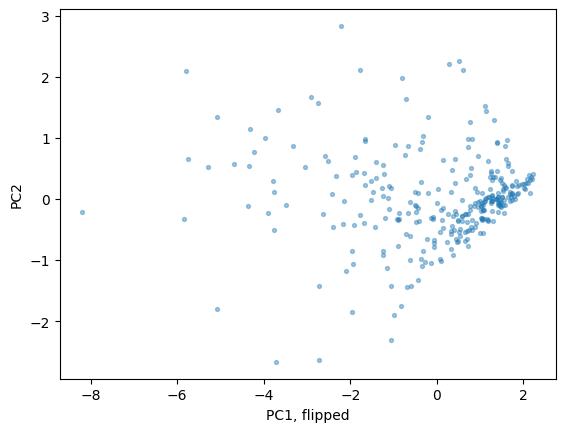

3.123 3.123


In [7]:
flipped = scores.copy()
flipped[:, 0] = -flipped[:, 0]
plt.scatter(flipped[:, 0], flipped[:, 1], s=8, alpha=0.4)
plt.xlabel("PC1, flipped"); plt.ylabel("PC2"); plt.show()
print(round(float(np.var(scores[:, 0])), 4), round(float(np.var(flipped[:, 0])), 4))

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
for k in [1, 2, 3, 4]:
    pcr = make_pipeline(StandardScaler(), PCA(n_components=k),
                        LinearRegression())
    mse = cross_val_score(pcr, d[four], y, cv=kf,
                          scoring="neg_mean_squared_error")
    print(k, round(np.sqrt(-mse.mean())))
line = LinearRegression()
mse = cross_val_score(line, d[four], y, cv=kf,
                      scoring="neg_mean_squared_error")
print("line", round(np.sqrt(-mse.mean())))

1 279325
2 199885
3 201022
4 201720
line 201720


In [9]:
wins = 0
for seed in range(10):
    folds = KFold(n_splits=5, shuffle=True, random_state=seed)
    two = make_pipeline(StandardScaler(), PCA(n_components=2), LinearRegression())
    a = np.sqrt(-cross_val_score(two, d[four], y, cv=folds,
                                 scoring="neg_mean_squared_error").mean())
    b = np.sqrt(-cross_val_score(line, d[four], y, cv=folds,
                                 scoring="neg_mean_squared_error").mean())
    wins += a < b
    print(seed, round(float(a)), round(float(b)))
print("two axes lower in", int(wins), "of 10")

0 203120 201619
1 207083 208793
2 199411 200915
3 200084 200782
4 204637 202816
5 200251 201124
6 196345 197747
7 207651 208316
8 200084 202897
9 200795 206637
two axes lower in 8 of 10


In [10]:
print(pca4.explained_variance_ratio_.cumsum().round(4))
keep = PCA(n_components=0.9)        # enough axes to hold 90%
keep.fit(Z4)
print(keep.n_components_)

[0.7808 0.9135 0.9925 1.    ]
2


In [11]:
X = scores[:, :2]                               # the map: PC1, PC2
start = ["Johns Hopkins University", "Marshall University",
         "West Virginia University"]
centers = X[[np.where(d["name"] == s)[0][0] for s in start]]
for step in range(8):
    dist = np.column_stack([((X - c)**2).sum(axis=1)
                            for c in centers])  # to each center
    group = dist.argmin(axis=1)                 # assign
    loss = dist.min(axis=1).sum()
    centers = np.array([X[group == g].mean(axis=0)
                        for g in range(3)])     # move
    print(step, round(float(loss), 1), np.bincount(group))

0 383.6 [ 36 166 100]
1 300.8 [ 32 172  98]
2 293.3 [ 30 176  96]
3 291.5 [ 28 178  96]
4 290.8 [ 28 178  96]
5 290.8 [ 28 178  96]
6 290.8 [ 28 178  96]
7 290.8 [ 28 178  96]


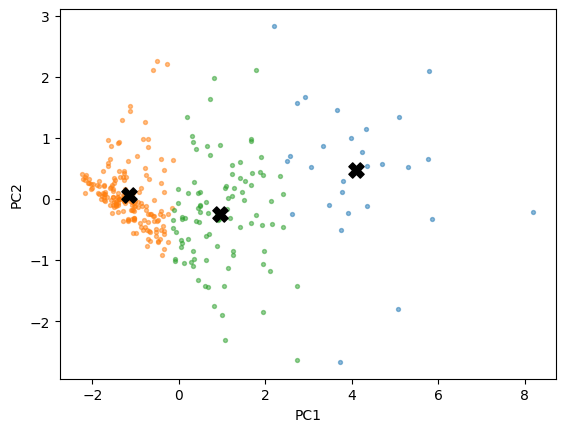

In [12]:
for g in range(3):
    plt.scatter(X[group == g, 0], X[group == g, 1], s=8, alpha=0.5)
plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=120, color="black")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

In [13]:
start2 = ["Johns Hopkins University", "Massachusetts Institute of Technology",
          "West Virginia University"]
centers2 = X[[np.where(d["name"] == s)[0][0] for s in start2]]
for step in range(12):
    dist2 = np.column_stack([((X - c)**2).sum(axis=1) for c in centers2])
    group2 = dist2.argmin(axis=1)
    loss2 = dist2.min(axis=1).sum()
    centers2 = np.array([X[group2 == g].mean(axis=0) for g in range(3)])
    print(step, round(float(loss2), 1), np.bincount(group2))
from sklearn.cluster import KMeans
ends = []
for seed in range(10):
    one = KMeans(n_clusters=3, n_init=1, random_state=seed)
    one.fit(X)
    ends.append(round(float(one.inertia_), 1))
print(ends)

0 823.3 [ 34  13 255]
1 472.9 [ 44  27 231]
2 416.0 [ 44  41 217]
3 368.1 [ 39  62 201]
4 325.3 [ 32  82 188]
5 295.9 [ 30  91 181]
6 292.0 [ 29  95 178]
7 291.0 [ 28  96 178]
8 290.8 [ 28  96 178]
9 290.8 [ 28  96 178]
10 290.8 [ 28  96 178]
11 290.8 [ 28  96 178]
[291.5, 290.7, 291.5, 290.7, 290.8, 290.8, 290.7, 290.7, 291.5, 290.8]


In [14]:
from sklearn.cluster import KMeans
km = KMeans(n_clusters=3, n_init=10, random_state=309)
km.fit(X)                                   # the map, ten starts
print(round(km.inertia_, 1), np.bincount(km.labels_))
km4 = KMeans(n_clusters=3, n_init=10, random_state=309)
km4.fit(Z4)                                 # all four columns
print(round(km4.inertia_, 1), np.bincount(km4.labels_))
means = d[four].groupby(km4.labels_).mean()     # rows: the groups
print(means.round(0).astype(int).values)
for full, short in labels.items():
    i = np.where(d["name"] == full)[0][0]
    print(short, km4.labels_[i])

290.7 [ 94 181  27]
393.7 [ 95  29 178]
[[30106  8116  1326   143]
 [47921 13786  2777   412]
 [11408  2980   576    38]]
JHU 1
WVU 0
MIT 0
Marshall 2


In [15]:
raw = KMeans(n_clusters=3, n_init=10, random_state=309)
raw.fit(d[four])                                # no scaler
print(np.bincount(raw.labels_))
bands = d["fallenr20"].groupby(raw.labels_).agg(["min", "max"])
print(bands.values)
for full, short in labels.items():
    i = np.where(d["name"] == full)[0][0]
    print(short, raw.labels_[i], km4.labels_[i])

[151  45 106]
[[  255 16926]
 [36303 89816]
 [17311 36461]]
JHU 2 1
WVU 2 0
MIT 0 0
Marshall 0 2


In [16]:
for k in range(1, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=309)
    model.fit(Z4)
    print(k, round(model.inertia_, 1))

1 1208.0
2 571.6
3 393.7
4 331.0
5 290.2
6 253.6
7 227.0
8 207.2


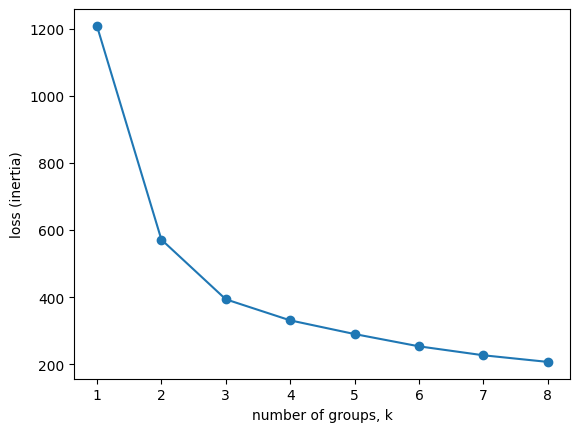

In [17]:
losses = []
for k in range(1, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=309)
    model.fit(Z4)
    losses.append(model.inertia_)
plt.plot(range(1, 9), losses, marker="o")
plt.xlabel("number of groups, k"); plt.ylabel("loss (inertia)"); plt.show()